# AIML Project

***

## Project Title

**ARES** -  Adaptive Reinforcement-based Endpoint Security

***

## Project Description

**ARES (Adaptive Reinforcement-based Endpoint Security)** is an intelligent endpoint security system designed to detect and prevent evolving cyber threats. It uses machine learning and adaptive techniques to identify QR-code phishing (quishing). The system analyzes threats in real time and assigns risk levels to potentially harmful activities. ARES can alert users, block malicious content, and continuously improve its detection based on previous threat patterns. The primary focus is on QR-code phishing.

***

## Team Members


| Sl. No. | Name                         | USN          |
|---------|------------------------------|--------------|
| 1       | Aryan S Jain                  | 1RUA25CSE0087 |
| 2       | Ashwin Chandrashekar Naik     | 1RUA25CSE0090 |
| 3       | Ashwin Rajesha Bhat           | 1RUA25CSE0091 |
| 4       | Ashwin Subramaniam            | 1RUA25CSE0092 |

***

## Phase 01: Loading the dataset

Load the dataset 'phishing_features.csv'.

***

In [1]:
# Importing the pandas file to work on tabulated data
import pandas as pd

# Reading the phishing_features.csv as df
df = pd.read_csv('/kaggle/input/datasets/victusadi/phishing-urls-dataset-with-extracted-features/phishing_features.csv')

## Phase 02: Data Interpretation

### Step 2.1

Preview the first 10 records.

***

In [2]:
# Read the first 'n' rows of the dataset
# Input format = df.head(n)
df.head(10)

,url,label,url_length,num_dots,has_https,has_ip,num_subdirs,num_params,suspicious_words,tld,special_char_count,digits_count,entropy
0,http://forum.uk.securebankinggroup.com/107519/...,1,89,3,0,0,5,0,2,com,4,29,4.792985
1,http://b45042.com/fish/29,1,25,1,0,0,4,0,0,com,0,7,4.003856
2,http://bet73018.com/lottery/99,1,30,1,0,0,4,0,0,com,0,7,4.053236
3,https://logiin--metsa-autho.webflow.io/,1,39,2,1,0,3,0,0,io,3,0,4.150411
4,https://mettamasklogiiann.webflow.io/,1,37,2,1,0,3,0,0,io,0,0,4.100817
5,http://bet73018.com/lottery/134,1,31,1,0,0,4,0,0,com,0,8,4.063563
6,https://metamasklogenies.webflow.io/,1,36,2,1,0,3,0,0,io,0,0,4.086049
7,https://mmettamaskilogin.webflow.io/,1,36,2,1,0,3,0,1,io,0,0,4.086049
8,https://www.robiox.com.py/users/322503287968/p...,1,52,3,1,0,5,0,0,py,0,12,4.582383
9,https://xbancobhd2025xxxxxxxxx.xo.je/,1,37,2,1,0,3,0,0,je,0,4,3.728139


### Step 2.2

List the column names.

***

In [3]:
# Reading the column names of the dataset
df.columns.tolist()

['url',
 'label',
 'url_length',
 'num_dots',
 'has_https',
 'has_ip',
 'num_subdirs',
 'num_params',
 'suspicious_words',
 'tld',
 'special_char_count',
 'digits_count',
 'entropy']

### Step 2.3

Check the dataset dimensions.

***

In [4]:
# Reading the number of rows and columns in the dataset
df.shape
# Output format = (Rows, Columns)

(160064, 13)

### Step 2.4

Inspect column data types.

***

In [5]:
# Reading the data types of the columns in the dataset
df.dtypes

url                    object
label                   int64
url_length              int64
num_dots                int64
has_https               int64
has_ip                  int64
num_subdirs             int64
num_params              int64
suspicious_words        int64
tld                    object
special_char_count      int64
digits_count            int64
entropy               float64
dtype: object

### Step 2.5

Review the datset structure & non-null counts.

***

In [6]:
# Counting the number of non-null data and reading data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 160064 entries, 0 to 160063
Data columns (total 13 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   url                 160064 non-null  object 
 1   label               160064 non-null  int64  
 2   url_length          160064 non-null  int64  
 3   num_dots            160064 non-null  int64  
 4   has_https           160064 non-null  int64  
 5   has_ip              160064 non-null  int64  
 6   num_subdirs         160064 non-null  int64  
 7   num_params          160064 non-null  int64  
 8   suspicious_words    160064 non-null  int64  
 9   tld                 159243 non-null  object 
 10  special_char_count  160064 non-null  int64  
 11  digits_count        160064 non-null  int64  
 12  entropy             160064 non-null  float64
dtypes: float64(1), int64(10), object(2)
memory usage: 15.9+ MB


### Step 2.6

Count missing values in each column.

***

In [7]:
# Finding count of missing values
mv_count = df.isnull().sum()
print(mv_count)

url                     0
label                   0
url_length              0
num_dots                0
has_https               0
has_ip                  0
num_subdirs             0
num_params              0
suspicious_words        0
tld                   821
special_char_count      0
digits_count            0
entropy                 0
dtype: int64


### Step 2.7

Count all missing value cells.

***

In [8]:
# Finding total number of missing cells
missing_values_cells = mv_count.sum()

print(missing_values_cells)

821


### Step 2.8

Calculate missing value cells percentage.

***

In [9]:
# Finding missing values % rounded off to 2 decimals
mv_percentage = (df.isnull().mean() * 100).round(2)
print(mv_percentage)

url                   0.00
label                 0.00
url_length            0.00
num_dots              0.00
has_https             0.00
has_ip                0.00
num_subdirs           0.00
num_params            0.00
suspicious_words      0.00
tld                   0.51
special_char_count    0.00
digits_count          0.00
entropy               0.00
dtype: float64


### Step 2.9

Build a missing value report.

***

In [10]:
# Creating a report of missing values
# pd.DataFrame() is used to create a data frame or a table of labelled rows & columns
mv_report = pd.DataFrame({
    "Count of Missing Values": mv_count,
    "Missing Values %": mv_percentage
})

print(mv_report)

                    Count of Missing Values  Missing Values %
url                                       0              0.00
label                                     0              0.00
url_length                                0              0.00
num_dots                                  0              0.00
has_https                                 0              0.00
has_ip                                    0              0.00
num_subdirs                               0              0.00
num_params                                0              0.00
suspicious_words                          0              0.00
tld                                     821              0.51
special_char_count                        0              0.00
digits_count                              0              0.00
entropy                                   0              0.00


### Step 2.10

Sort the missing value report.

***

In [11]:
# Sorting the missing values report
# {dataframe_name}.sort_values(by = "{column_name}", ascending = {True/False}) is used to sort a dataframe/table
sorted_mv_report = mv_report.sort_values(by = "Count of Missing Values", ascending = False)

print(sorted_mv_report)

                    Count of Missing Values  Missing Values %
tld                                     821              0.51
label                                     0              0.00
url_length                                0              0.00
num_dots                                  0              0.00
url                                       0              0.00
has_https                                 0              0.00
has_ip                                    0              0.00
num_params                                0              0.00
num_subdirs                               0              0.00
suspicious_words                          0              0.00
special_char_count                        0              0.00
digits_count                              0              0.00
entropy                                   0              0.00


### Step 2.11

Show only columns with missing values.

***

In [12]:
# Printing non-null positive values from the sorted missing values report
print(sorted_mv_report[sorted_mv_report["Count of Missing Values"] > 0])

     Count of Missing Values  Missing Values %
tld                      821              0.51


### Step 2.12

Identify target label.

***

In [13]:
# Inspecting labels and class distribution of the target column 
target_column = "label"

# Finding unique labels in the target column
unique_labels = df[target_column].unique()

print(unique_labels)

[1 0]


### Step 2.13

Count records in target column.

***

In [14]:
# Finding how many times the unique value appears in the target column
uv_count = df[target_column].value_counts()

print(uv_count)

label
1    159244
0       820
Name: count, dtype: int64


### Step 2.14

Calculate class proportions.

***

In [15]:
# Finding the unique value appearance % in the target column
uv_percentage = df[target_column].value_counts(normalize = True).mul(100).round(2)

print(uv_percentage)

label
1    99.49
0     0.51
Name: proportion, dtype: float64


### Note

We can observe that the dataset has a major class imbalance the two labels.

***

## Phase 03: Data Preprocessing

### Step 3.1

Visualize the class distribution.

***

In [16]:
# Importing matplotlib to generate graphs
import matplotlib.pyplot as plt

# Defining a function to generate a bar graph
def generate_bar_graph(y, title, x_label, y_label):
    # Plotting y as bar graph
    y.plot(kind = "bar")

    # Assign the bar graph the title
    plt.title(title)

    # Assign the x-axis the label
    plt.xlabel(x_label)

    # Assign the y-axis the label
    plt.ylabel(y_label)

    # Generate the bar graph
    plt.show()

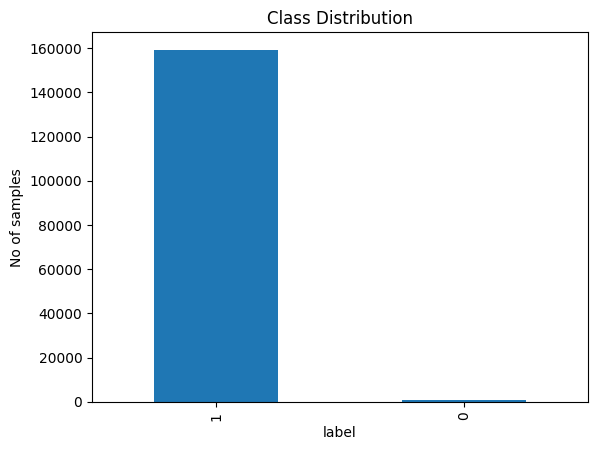

In [17]:
# Call the generate_bar_graph function to generate an initial class distribution bar graph
generate_bar_graph(uv_count, "Class Distribution", target_column, "No of samples")

### Step 3.2

Create an initial train-test split for the model.

***

In [18]:
# Importing the train_test_split function from the model_selection library of sklearn to randomly distribute the dataset into a training set and a test set
from sklearn.model_selection import train_test_split

# Take x as all the columns except the target column
X = df.drop(columns = [target_column])

# Take y as target column values
y = df[target_column]

# Splitting the dataset into 80% training set and 20% testing set
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.20, random_state = 42, stratify = y
)
# random_state = 42 prevents the model from generating a different train and test model everytime the model is run
# stratify = y tells the model to preserve the same class proportions in both the training and testing sets

### Step 3.3

Check the dimensions of the initial training & testing sets.

***

In [19]:
# Printing the number of rows and colums in the training set data
print("Training set:", X_train.shape, y_train.shape)

Training set: (128051, 12) (128051,)


In [20]:
# Printing the number of rows & columns in the testing set data
print("Testing set:", X_test.shape, y_test.shape)

Testing set: (32013, 12) (32013,)


### Step 3.4

Calculate the initial proportions of the training & testing sets.

***

In [21]:
# Finding the percentage of unique values in the target column in the training set
training_uv_percentage = y_train.value_counts(normalize = True).mul(100).round(2)

print(training_uv_percentage)

label
1    99.49
0     0.51
Name: proportion, dtype: float64


In [22]:
# Finding the percentage of unique values in the target column in the testing set
testing_uv_percentage = y_test.value_counts(normalize = True).mul(100).round(2)

print(testing_uv_percentage)

label
1    99.49
0     0.51
Name: proportion, dtype: float64


### Step 3.5

Select the numerical features & create a secondary train-test split.

***

In [23]:
# url is a text feature, so we use its numerical engineered features
numerical_feature_columns = [
    "url_length", "num_dots", "has_https", "has_ip", "num_subdirs", "num_params", "suspicious_words", "special_char_count", "digits_count", "entropy"
]

# Take x as the values of all numeric engineered columns
X = df[numerical_feature_columns]

# Take y as target column values
y = df[target_column]

#Splitting the dataset into 80% training set and 20% testing set for the new x & y values
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.20, random_state = 42, stratify = y
)

### Step 3.6

Check the dimensions of the secondary training & testing sets.

***

In [24]:
# Printing the number of rows and colums in the training set data
print("Training set:", X_train.shape, y_train.shape)

Training set: (128051, 10) (128051,)


In [25]:
# Printing the number of rows & columns in the testing set data
print("Testing set:", X_test.shape, y_test.shape)

Testing set: (32013, 10) (32013,)


### Step 3.7

Calculate the initial proportions of the secondary training & testing sets.

***

In [26]:
# Finding the percentage of unique values in the target column in the training set
training_uv_percentage = y_train.value_counts(normalize = True).mul(100).round(2)

print(training_uv_percentage)

label
1    99.49
0     0.51
Name: proportion, dtype: float64


In [27]:
# Finding the percentage of unique values in the target column in the testing set
testing_uv_percentage = y_test.value_counts(normalize = True).mul(100).round(2)

print(testing_uv_percentage)

label
1    99.49
0     0.51
Name: proportion, dtype: float64


***

### Note

It can be observed that my dataset has major class imbalance.

We shall resolve this issue using:
- The **Class Weights** method

***

## Phase 04: Model Development & Training

### Step 4.1

Train a class-weighted model.

***

In [28]:
# Importing the RandomForestClassifier function from the ensemble library to create a random forest for a model
from sklearn.ensemble import RandomForestClassifier

# Training a class-weighted model
model = RandomForestClassifier(
    class_weight = "balanced",
    random_state = 42,
    n_jobs = -1
)
# class_weight = "balanced" is used to handle the imbalanced classes, by telling the model to focus more on the under-represented classes
# n_jobs = -1 controls parallel processing, by telling the program to use all available CPU cores during fitting and predicting

### Step 4.2

Visualize the distribution.

***

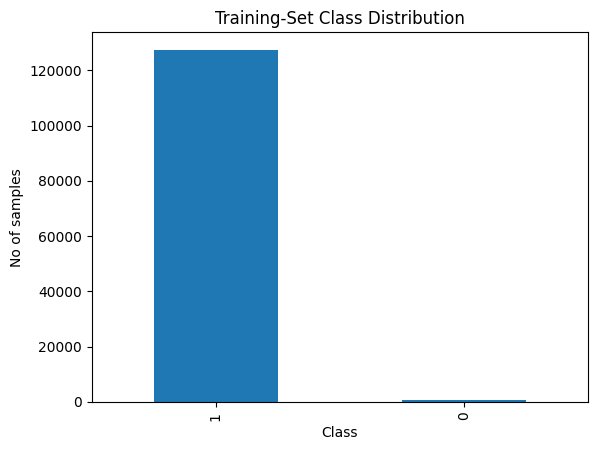

In [29]:
# Call the generate_bar_graph function to generate a class distribution bar graph for the training dataset
generate_bar_graph(y_train.value_counts(), "Training-Set Class Distribution", "Class", "No of samples")

### Step 4.3

Train the machine-learning model.

***

In [30]:
# Training the ML model
model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', n_jobs=-1, random_state=42)

### Step 4.4

Evaluate the predicted values on training data and probability of class 1.

***

In [31]:
# Evaluate the predicted value on the training data
y_train_predicted = model.predict(X_train)

print(y_train_predicted)

[1 1 1 ... 1 1 1]


In [32]:
# Evaluate the probability value for every class on the training data
y_train_probability = model.predict_proba(X_train)

print(y_train_probability)

[[0. 1.]
 [0. 1.]
 [0. 1.]
 ...
 [0. 1.]
 [0. 1.]
 [0. 1.]]


In [33]:
# Evaluate the probability value of class 1 on the training data
c1_train_probability = y_train_probability[:, 1]

print(c1_train_probability)

[1. 1. 1. ... 1. 1. 1.]


### Step 4.5

Generate a Confusion matrix on the training data.

***

In [34]:
# Importing the function confusion_matrix from the metrics library
from sklearn.metrics import confusion_matrix

# Evaluating the confusion matrix on the training data
cm_train = confusion_matrix(y_train, y_train_predicted, labels = [0, 1])

# Display the confusion matrix
print(cm_train)

[[   656      0]
 [     0 127395]]


### Step 4.6

Visualize the Confusion matrix on the training data.

***

In [35]:
# Importing the function ConfusionMatrixDisplay from the metrics library
from sklearn.metrics import ConfusionMatrixDisplay

# Defining a function to generate a Confusion matrix
def generate_confusion_matrix(confusion_matrix, labels, color, title, values_format):
    # Create a Confusion Matrix Display
    display = ConfusionMatrixDisplay(confusion_matrix = confusion_matrix, display_labels = labels);

    # Plot the confusion matrix, set the color of the darker values, and select integer display
    display.plot(cmap = color, values_format = values_format)
    # If values_format = "d", then integer counts are displayed instead of scientific notation

    # Set Confusion Matrix title
    plt.title(title)

    # Display the Confusion Matrix
    plt.show()

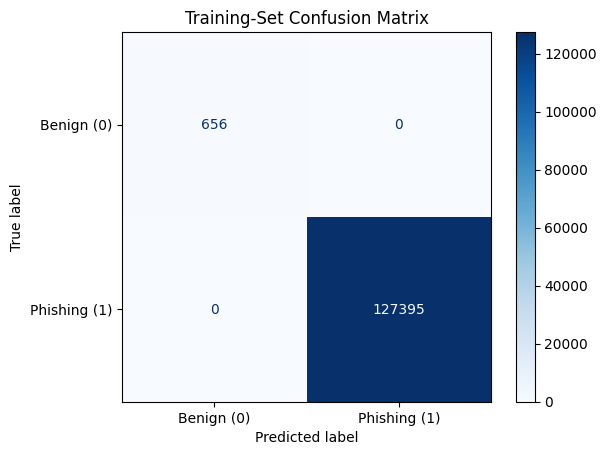

In [36]:
# Call the function generate_confusion_matrix to generate a confusion matrix on the training dataset
generate_confusion_matrix(cm_train, ["Benign (0)", "Phishing (1)"], "Blues", "Training-Set Confusion Matrix", "d")

### Step 4.7

Create a classification report on the training dataset.

***

In [37]:
# Importing the function classification_report from the sklearn.metrics library
from sklearn.metrics import classification_report

# Generating a classification report on training data
cr_train = classification_report(y_train, y_train_predicted)

# Print the classification report
print(cr_train)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       656
           1       1.00      1.00      1.00    127395

    accuracy                           1.00    128051
   macro avg       1.00      1.00      1.00    128051
weighted avg       1.00      1.00      1.00    128051



### Step 4.8

Calculate the accuracy, balanced accuracy, precision, average precision, recall, and F1-score on the training dataset, rounded to 4 decimals

***

In [38]:
# Importing the accuracy_score, balanced_accuracy_score, precision_score, average_precision, recall_score, and f1_score functions from the sklearn.metrics library
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, average_precision_score, recall_score, f1_score
)

# Defining a function to evaluate the metrics that return all the metric values
def evaluate_metrics(y, y_predicted, c1_probability, label, division):
    # Evaluate the accuracy score, balanced accuracy score, precision score, average precision score, recall score, and F1-score.
    accuracy = accuracy_score(y, y_predicted)

    balanced_accuracy = balanced_accuracy_score(y, y_predicted)

    precision = precision_score(y, y_predicted, pos_label = label, zero_division = division)
    # pos_label tells the library which class is the positive class in binary classification
    # zero_division tells the function the return value when the denominator is 0
    
    avg_precision = average_precision_score(y, c1_probability)

    recall = recall_score(y, y_predicted, pos_label = label, zero_division = division)

    f1 = f1_score(y, y_predicted, pos_label = label, zero_division = division)

    return accuracy, balanced_accuracy, precision, avg_precision, recall, f1

In [39]:
# Defining a function to print the metrics in rounded figures
def display_metrics(set_type, accuracy, balanced_accuracy, precision, avg_precision, recall, f1_score, round_off):
    print(f"{set_type} Set Metric Values:\n\nAccuracy = {round(accuracy, round_off)}\n")
    print(f"Balanced Accuracy = {round(balanced_accuracy, round_off)}\n")
    print(f"Precision = {round(precision, round_off)}\n")
    print(f"Average Precision = {round(avg_precision, round_off)}\n")
    print(f"Recall = {round(recall, round_off)}\n")
    print(f"F1-score = {round(f1_score, round_off)}")

In [40]:
# Calling the evaluate_metrics function to evaluate the metrics on the training data
accuracy_train, balanced_accuracy_train, precision_train, avg_precision_train, recall_train, f1_score_train = evaluate_metrics(
    y_train, y_train_predicted, c1_train_probability, 1, 0
)

# Calling the function display_metrics to print all the metric values rounded off to 4 decimal places
display_metrics("Training", accuracy_train, balanced_accuracy_train, precision_train, avg_precision_train, recall_train, f1_score_train, 4)

Training Set Metric Values:

Accuracy = 1.0

Balanced Accuracy = 1.0

Precision = 1.0

Average Precision = 1.0

Recall = 1.0

F1-score = 1.0


### Step 4.9

Repeat steps from 4.4 to 4.8 for the testing data

***

In [41]:
# Evaluate the predicted values on test data
y_test_predicted = model.predict(X_test)

print(y_test_predicted)

[0 1 1 ... 1 1 1]


In [42]:
# Evaluate the class probability on test data
y_test_probability = model.predict_proba(X_test)

print(y_test_probability)

[[0.96 0.04]
 [0.   1.  ]
 [0.   1.  ]
 ...
 [0.   1.  ]
 [0.   1.  ]
 [0.   1.  ]]


In [43]:
# Evaluate the class 1 probability on test data
c1_test_probability = y_test_probability[:, 1]

print(c1_test_probability)

[0.04 1.   1.   ... 1.   1.   1.  ]


In [44]:
# Generate a confusion matrix on test data
cm_test = confusion_matrix(y_test, y_test_predicted, labels = [0, 1])

print(cm_test)

[[  164     0]
 [    0 31849]]


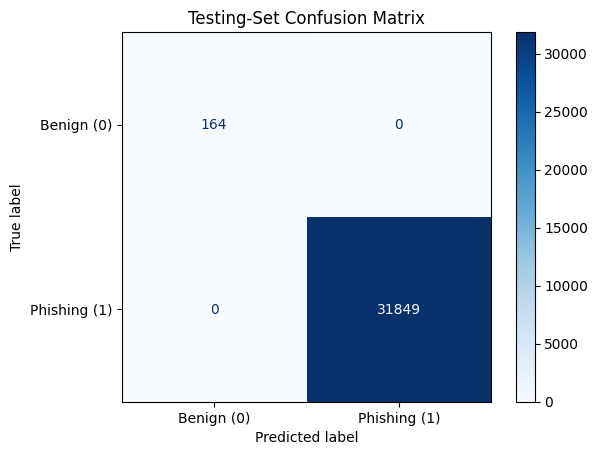

In [45]:
# Display the confusion matrix
generate_confusion_matrix(cm_test, ["Benign (0)", "Phishing (1)"], "Blues", "Testing-Set Confusion Matrix", "d")

In [46]:
# Generate a classification report on test data
cr_test = classification_report(y_test, y_test_predicted)

print(cr_test)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       164
           1       1.00      1.00      1.00     31849

    accuracy                           1.00     32013
   macro avg       1.00      1.00      1.00     32013
weighted avg       1.00      1.00      1.00     32013



In [47]:
# Calling the evaluate_metrics function to evaluate the metrics on the test data
accuracy_test, balanced_accuracy_test, precision_test, avg_precision_test, recall_test, f1_score_test = evaluate_metrics(
    y_test, y_test_predicted, c1_test_probability, 1, 0
)

# Calling the function display_metrics to print all the metric values rounded off to 4 decimal places
display_metrics("Test", accuracy_test, balanced_accuracy_test, precision_test, avg_precision_test, recall_test, f1_score_test, 4)

Test Set Metric Values:

Accuracy = 1.0

Balanced Accuracy = 1.0

Precision = 1.0

Average Precision = 1.0

Recall = 1.0

F1-score = 1.0


### Step 4.10

Save the trained model as a joblib file

***

In [48]:
# Importing the joblib library to save and load trained ML models
import joblib

# Creating a dictionary to store the trained ML model information to reuse the model later when loading it in another notebook or application
model_bundle = {
    # Saving the trained ML model object as model
    "model": model,
    # Saving the numerical feature column names as features
    "features": numerical_feature_columns,
    # Saving the label encoding
    "label_mapping": {
        0: "Benign",
        1: "Phishing"
    }
}

In [49]:
# Saving the complete model bundle as a .joblib file in Kaggle's working directory
joblib.dump(model_bundle, "/kaggle/working/model.joblib")

['/kaggle/working/model.joblib']

## Initial Evaluation 01

We achieved perfect classification on the held-out test split. Subsequent dataset diagnostics revealed systematic representation differences between the benign and phishing classes, including URL scheme presence, path-separator counts, and TLD missingness. These differences may enable shortcut learning and limit generalization. Therefore, the initial score is treated as a preliminary dataset-specific result rather than evidence of perfect real-world phishing detection.

***

***

## Tests asked by AI

### Note

Everything below will be deleted later on.

***

In [50]:

# ARES: Investigate dataset shortcuts

# 1. Compare URL schemes by class
has_scheme = df["url"].str.match(
    r"^https?://",
    case=False,
    na=False
)

print("URL scheme presence by label:")
print(pd.crosstab(
    df["label"],
    has_scheme,
    rownames=["Label"],
    colnames=["Has HTTP/HTTPS scheme"]
))

# 2. Compare engineered feature ranges by class
features_to_check = [
    "url_length",
    "num_subdirs",
    "has_https",
    "num_dots",
    "digits_count"
]

print("\nFeature ranges by label:")
print(df.groupby("label")[features_to_check].agg(
    ["min", "median", "max"]
))

# 3. Check missing TLD values by class
print("\nMissing TLD percentage by label:")
print(
    df.groupby("label")["tld"]
      .apply(lambda s: round(s.isna().mean() * 100, 2))
)

# 4. Check whether num_subdirs may count protocol slashes
print("\nnum_subdirs distribution by label:")
print(pd.crosstab(df["label"], df["num_subdirs"]))

URL scheme presence by label:
Has HTTP/HTTPS scheme  False   True 
Label                               
0                        820       0
1                          0  159244

Feature ranges by label:
      url_length               num_subdirs             has_https             \
             min median    max         min median  max       min median max   
label                                                                         
0              6   16.0     22           0    0.0    0         0    0.0   0   
1             12   37.0  25523           2    3.0  104         0    0.0   1   

      num_dots            digits_count               
           min median max          min median   max  
label                                                
0            1    1.0   2            0    1.0     3  
1            1    3.0  59            0   12.0  3413  

Missing TLD percentage by label:
label
0    100.0
1      0.0
Name: tld, dtype: float64

num_subdirs distribution by label:
num_su